In [2]:
import pandas as pd
import matplotlib.pyplot as plt
#import seaborn as sns

In [3]:
df=pd.read_excel('/Users/kanchana/Library/CloudStorage/OneDrive-Personal/Desktop/DATA SETS/Sample - Superstore.xlsx')

In [4]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [5]:
df.info()
#df['Order Date'] = pd.to_datetime(df['Order Date'])
#df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   str           
 2   Order Date     9994 non-null   datetime64[us]
 3   Ship Date      9994 non-null   datetime64[us]
 4   Ship Mode      9994 non-null   str           
 5   Customer ID    9994 non-null   str           
 6   Customer Name  9994 non-null   str           
 7   Segment        9994 non-null   str           
 8   Country        9994 non-null   str           
 9   City           9994 non-null   str           
 10  State          9994 non-null   str           
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   str           
 13  Product ID     9994 non-null   str           
 14  Category       9994 non-null   str           
 15  Sub-Category   9994 non-null   s

In [6]:
df['year_order_date']=(df['Order Date'].dt.year)

print(df['year_order_date'].value_counts())

year_order_date
2017    3312
2016    2587
2015    2102
2014    1993
Name: count, dtype: int64


<Axes: xlabel='year_order_date'>

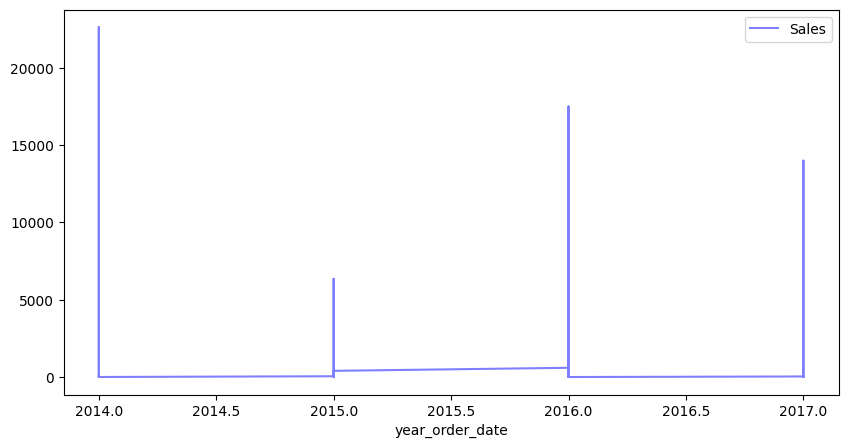

In [7]:
# note that matplotlib plot the indices of the dataframe as x-axis and the values as y-axis. 
# To plot a specific column, we can use the following syntax:
df.sort_values(by='year_order_date',ascending=False).plot(kind='line',x='year_order_date', y='Sales',figsize=(10,5), color='blue', alpha=0.5)

# note that matplotlib plot the indices of the dataframe as x-axis and the values as y-axis. 

In [8]:
years=list(map(str, range(2000, 2021)))
#map() doesn't immediately create a list—it returns a map object (an iterator).
# list() converts it into a list.


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 22 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Row ID           9994 non-null   int64         
 1   Order ID         9994 non-null   str           
 2   Order Date       9994 non-null   datetime64[us]
 3   Ship Date        9994 non-null   datetime64[us]
 4   Ship Mode        9994 non-null   str           
 5   Customer ID      9994 non-null   str           
 6   Customer Name    9994 non-null   str           
 7   Segment          9994 non-null   str           
 8   Country          9994 non-null   str           
 9   City             9994 non-null   str           
 10  State            9994 non-null   str           
 11  Postal Code      9994 non-null   int64         
 12  Region           9994 non-null   str           
 13  Product ID       9994 non-null   str           
 14  Category         9994 non-null   str           
 15

In [10]:
df_cost = (
    df.groupby([df['Order Date'].dt.year, 'Category'])['Sales']
      .sum()
      .reset_index()
)

In [11]:
df_cost.sort_values(by='Sales', ascending=False,inplace=True)
df_cost

,Order Date,Category,Sales
11,2017,Technology,271730.8110
10,2017,Office Supplies,246097.1750
8,2016,Technology,226364.1800
9,2017,Furniture,215387.2692
6,2016,Furniture,198901.4360
7,2016,Office Supplies,183939.9820
2,2014,Technology,175278.2330
3,2015,Furniture,170518.2370
5,2015,Technology,162780.8090
0,2014,Furniture,157192.8531


In [12]:
df_cost_5=df_cost.head(5)
df_cost_5

,Order Date,Category,Sales
11,2017,Technology,271730.8110
10,2017,Office Supplies,246097.1750
8,2016,Technology,226364.1800
9,2017,Furniture,215387.2692
6,2016,Furniture,198901.4360


In [13]:
df_pivot = df_cost.pivot(
    index='Order Date',
    columns='Category',
    values='Sales'
)
df_pivot

Category,Furniture,Office Supplies,Technology
Order Date,,,
2014,157192.8531,151776.412,175278.233
2015,170518.2370,137233.463,162780.809
2016,198901.4360,183939.982,226364.180
2017,215387.2692,246097.175,271730.811


<Axes: xlabel='Order Date'>

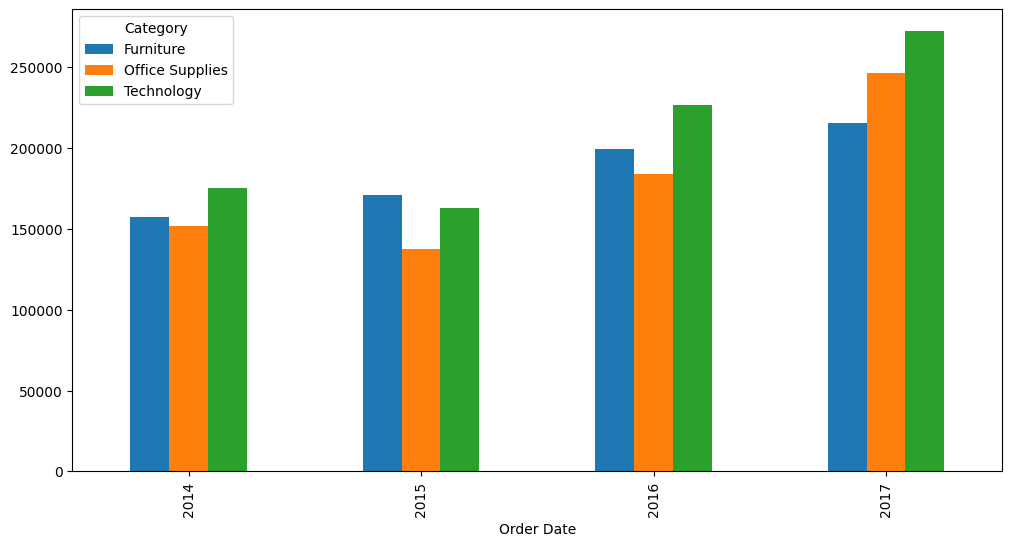

In [14]:
df_pivot.plot(kind='bar', figsize=(12,6))

In [15]:
df.shape

(9994, 22)

In [16]:
df_cost1=df.groupby(['year_order_date', 'State'])['Sales'].sum().reset_index()

In [17]:
df_cost1

,year_order_date,State,Sales
0,2014,Alabama,6139.090
1,2014,Arizona,8295.235
2,2014,Arkansas,6302.690
3,2014,California,91303.531
4,2014,Colorado,6502.294
...,...,...,...
176,2017,Vermont,842.210
177,2017,Virginia,7600.200
178,2017,Washington,65539.896
179,2017,West Virginia,1209.824


In [18]:
#top 5 states with highest sales for each year
top5_states = (
    df_cost1
    .sort_values(['year_order_date', 'Sales'], ascending=[True, False])
    .groupby('year_order_date')
    .head(5)
)

In [19]:
top5_states

,year_order_date,State,Sales
3,2014,California,91303.5310
29,2014,New York,64788.4870
39,2014,Texas,50625.1766
7,2014,Florida,34248.2605
42,2014,Washington,29871.5760
47,2015,California,88443.8445
74,2015,New York,80320.6870
83,2015,Texas,34454.9590
87,2015,Washington,23415.5140
79,2015,Pennsylvania,20510.8160


<Axes: xlabel='year_order_date'>

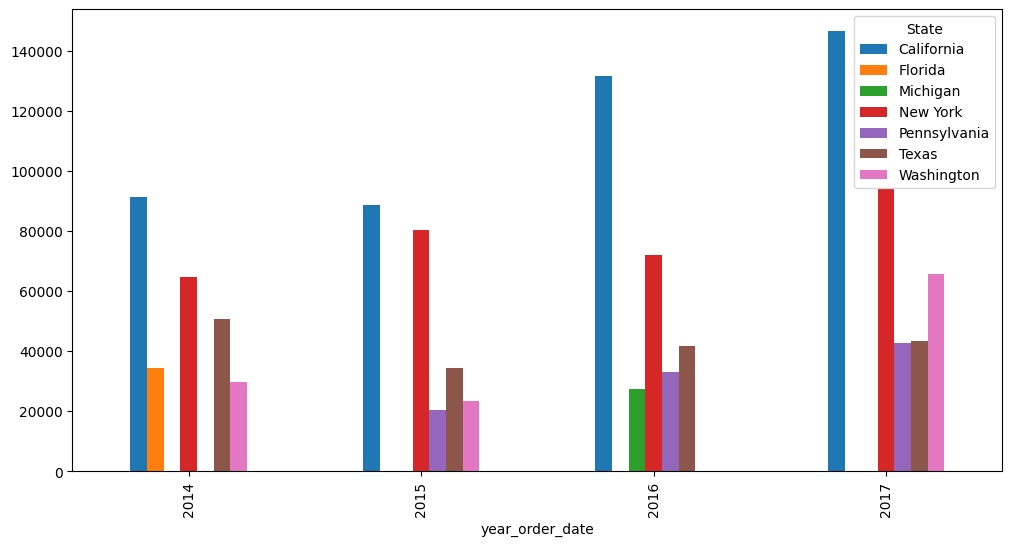

In [20]:
top5_states.pivot(index='year_order_date', columns='State', values='Sales').plot(kind='bar', figsize=(12,6))

<Axes: xlabel='year_order_date'>

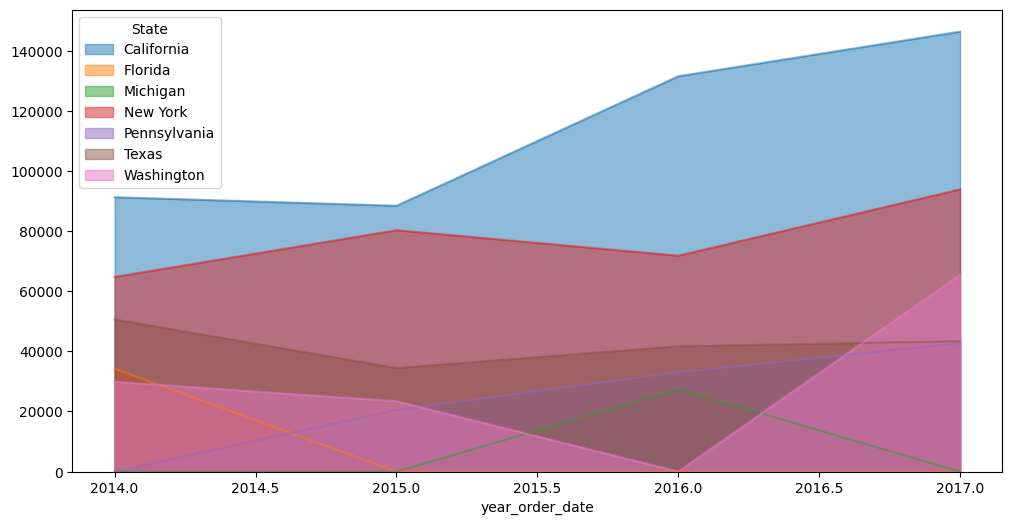

In [21]:
top5_states.pivot(index='year_order_date', columns='State', values='Sales').plot(kind='area', figsize=(12,6),stacked=False)

In [22]:
#after transpose
top5_states_pivot=top5_states.pivot(index='year_order_date', columns='State', values='Sales')

<Axes: xlabel='year_order_date'>

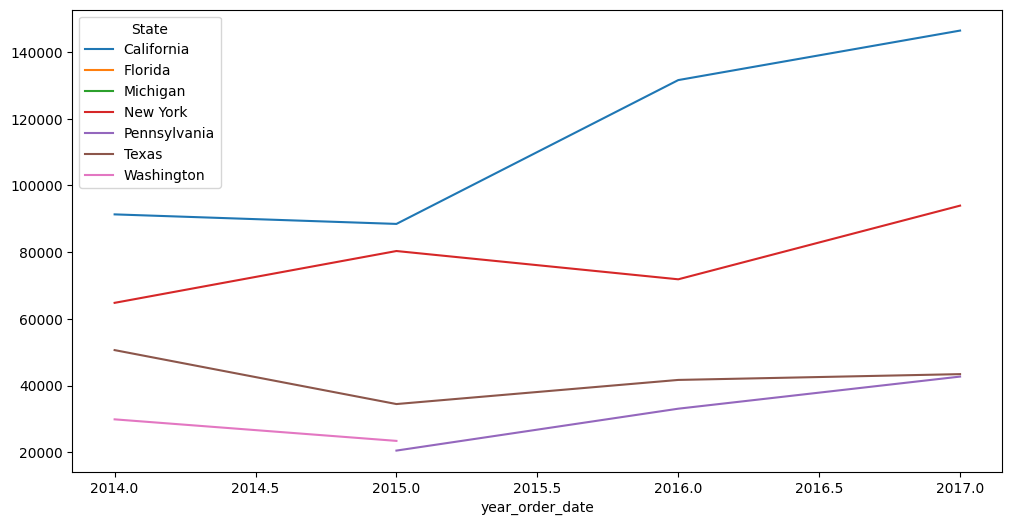

In [23]:
top5_states_pivot.plot(kind='line', figsize=(12,6))

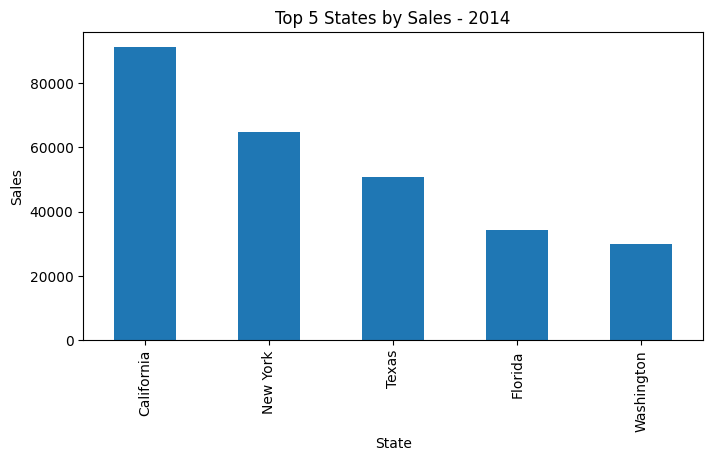

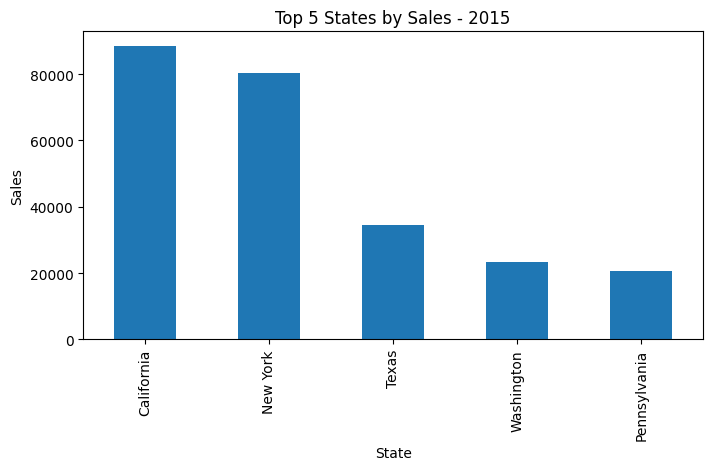

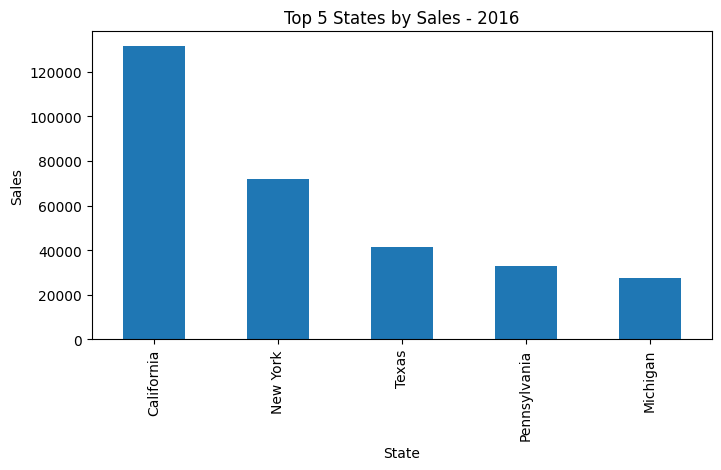

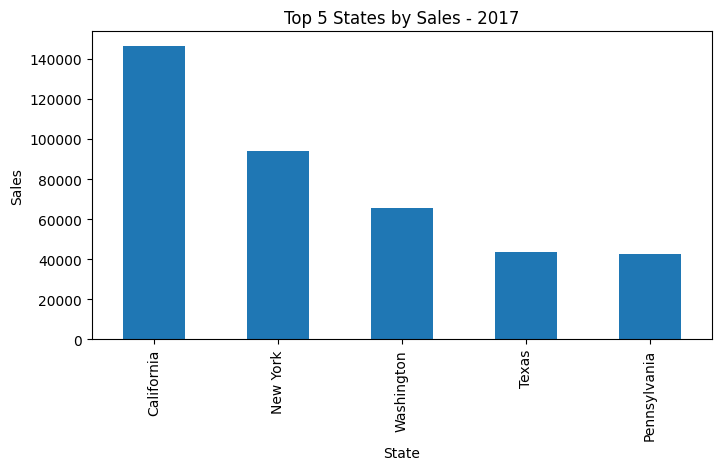

In [24]:

for year, data in top5_states.groupby('year_order_date'):
    data.plot(
        kind='bar',
        x='State',
        y='Sales',
        title=f'Top 5 States by Sales - {year}',
        legend=False,
        figsize=(8, 4)
    )
    plt.ylabel('Sales')
    plt.show()

In [25]:
# SUBPLOTS

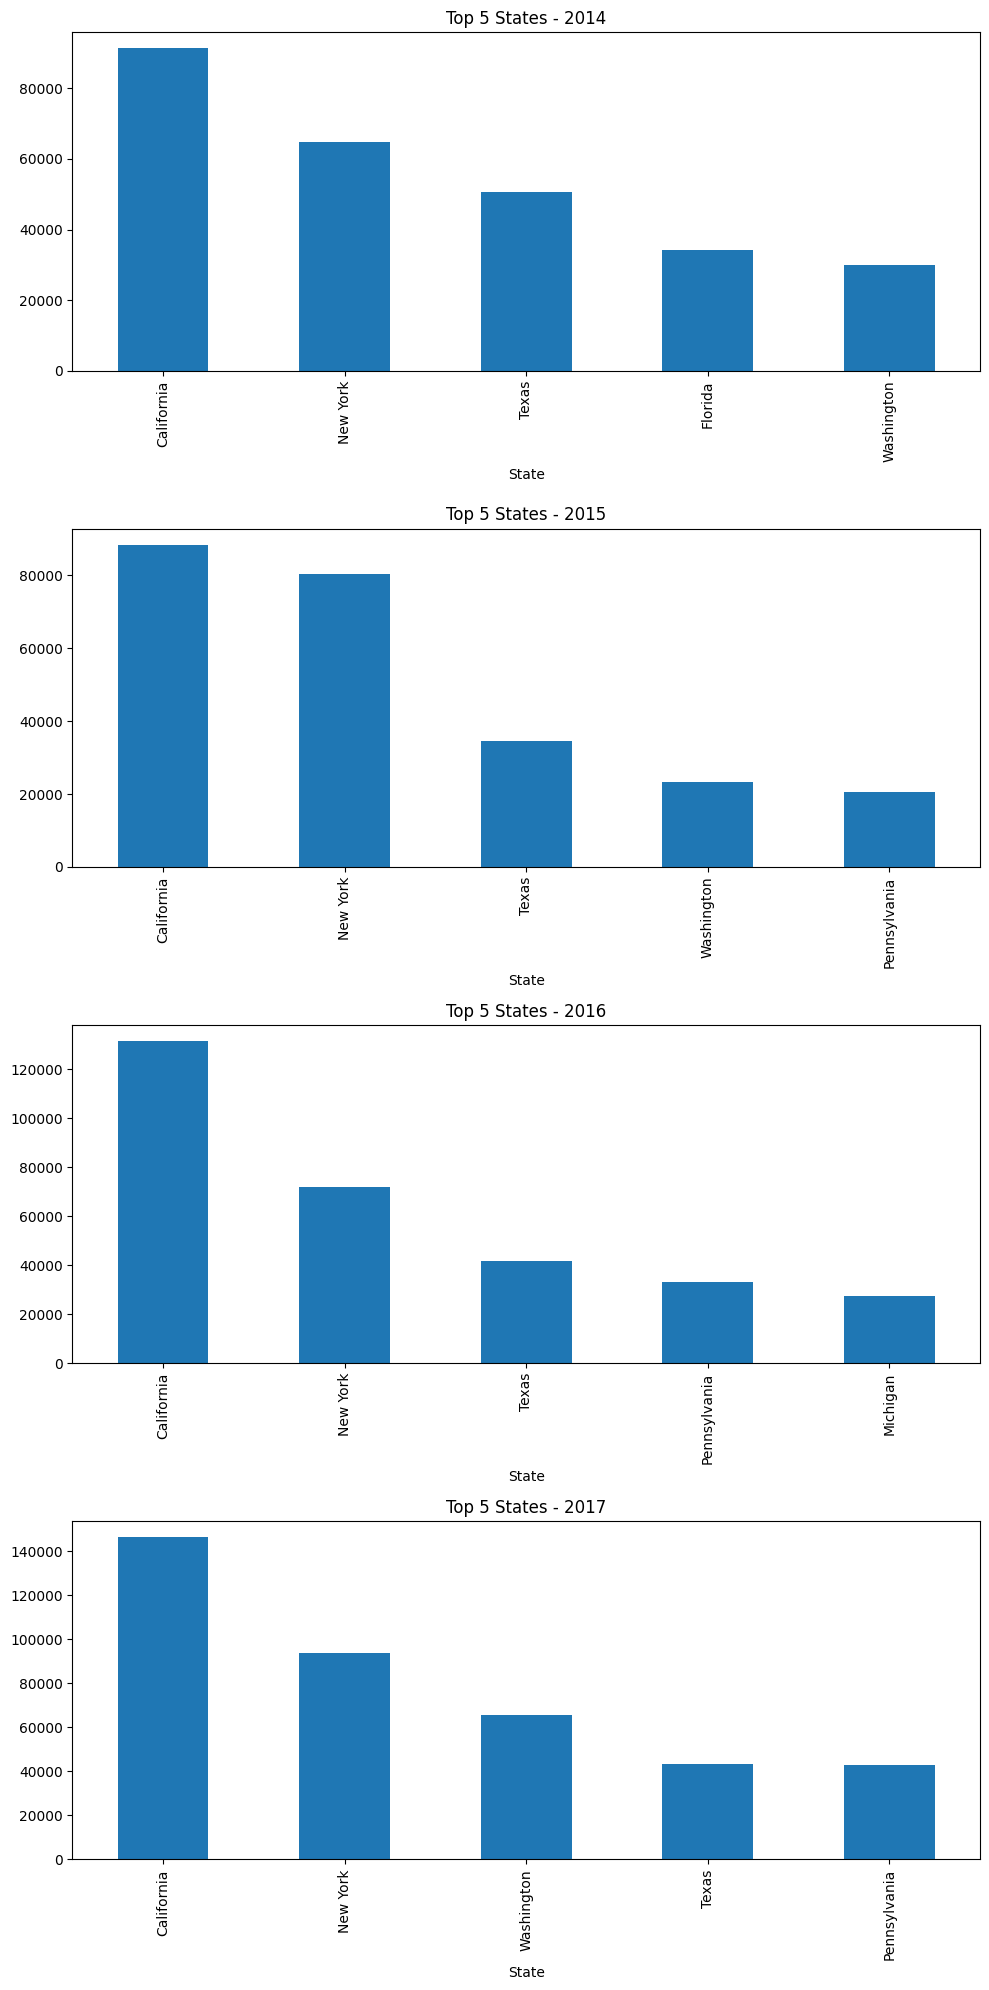

In [26]:
years = top5_states['year_order_date'].unique()

fig, axes = plt.subplots(
    nrows=len(years),
    ncols=1,
    figsize=(10, 5 * len(years))
)

# If there's only one year, make axes iterable
if len(years) == 1:
    axes = [axes]

for ax, year in zip(axes, years):
    data = top5_states[top5_states['year_order_date'] == year]

    data.plot(
        kind='bar',
        x='State',
        y='Sales',
        ax=ax,
        legend=False,
        title=f'Top 5 States - {year}'
    )

plt.tight_layout() # alows the label to not overlap
plt.show()

In [27]:
nrows=len(years)/2
print(nrows)

ncol=len(years)//2
ncol

2.0


2

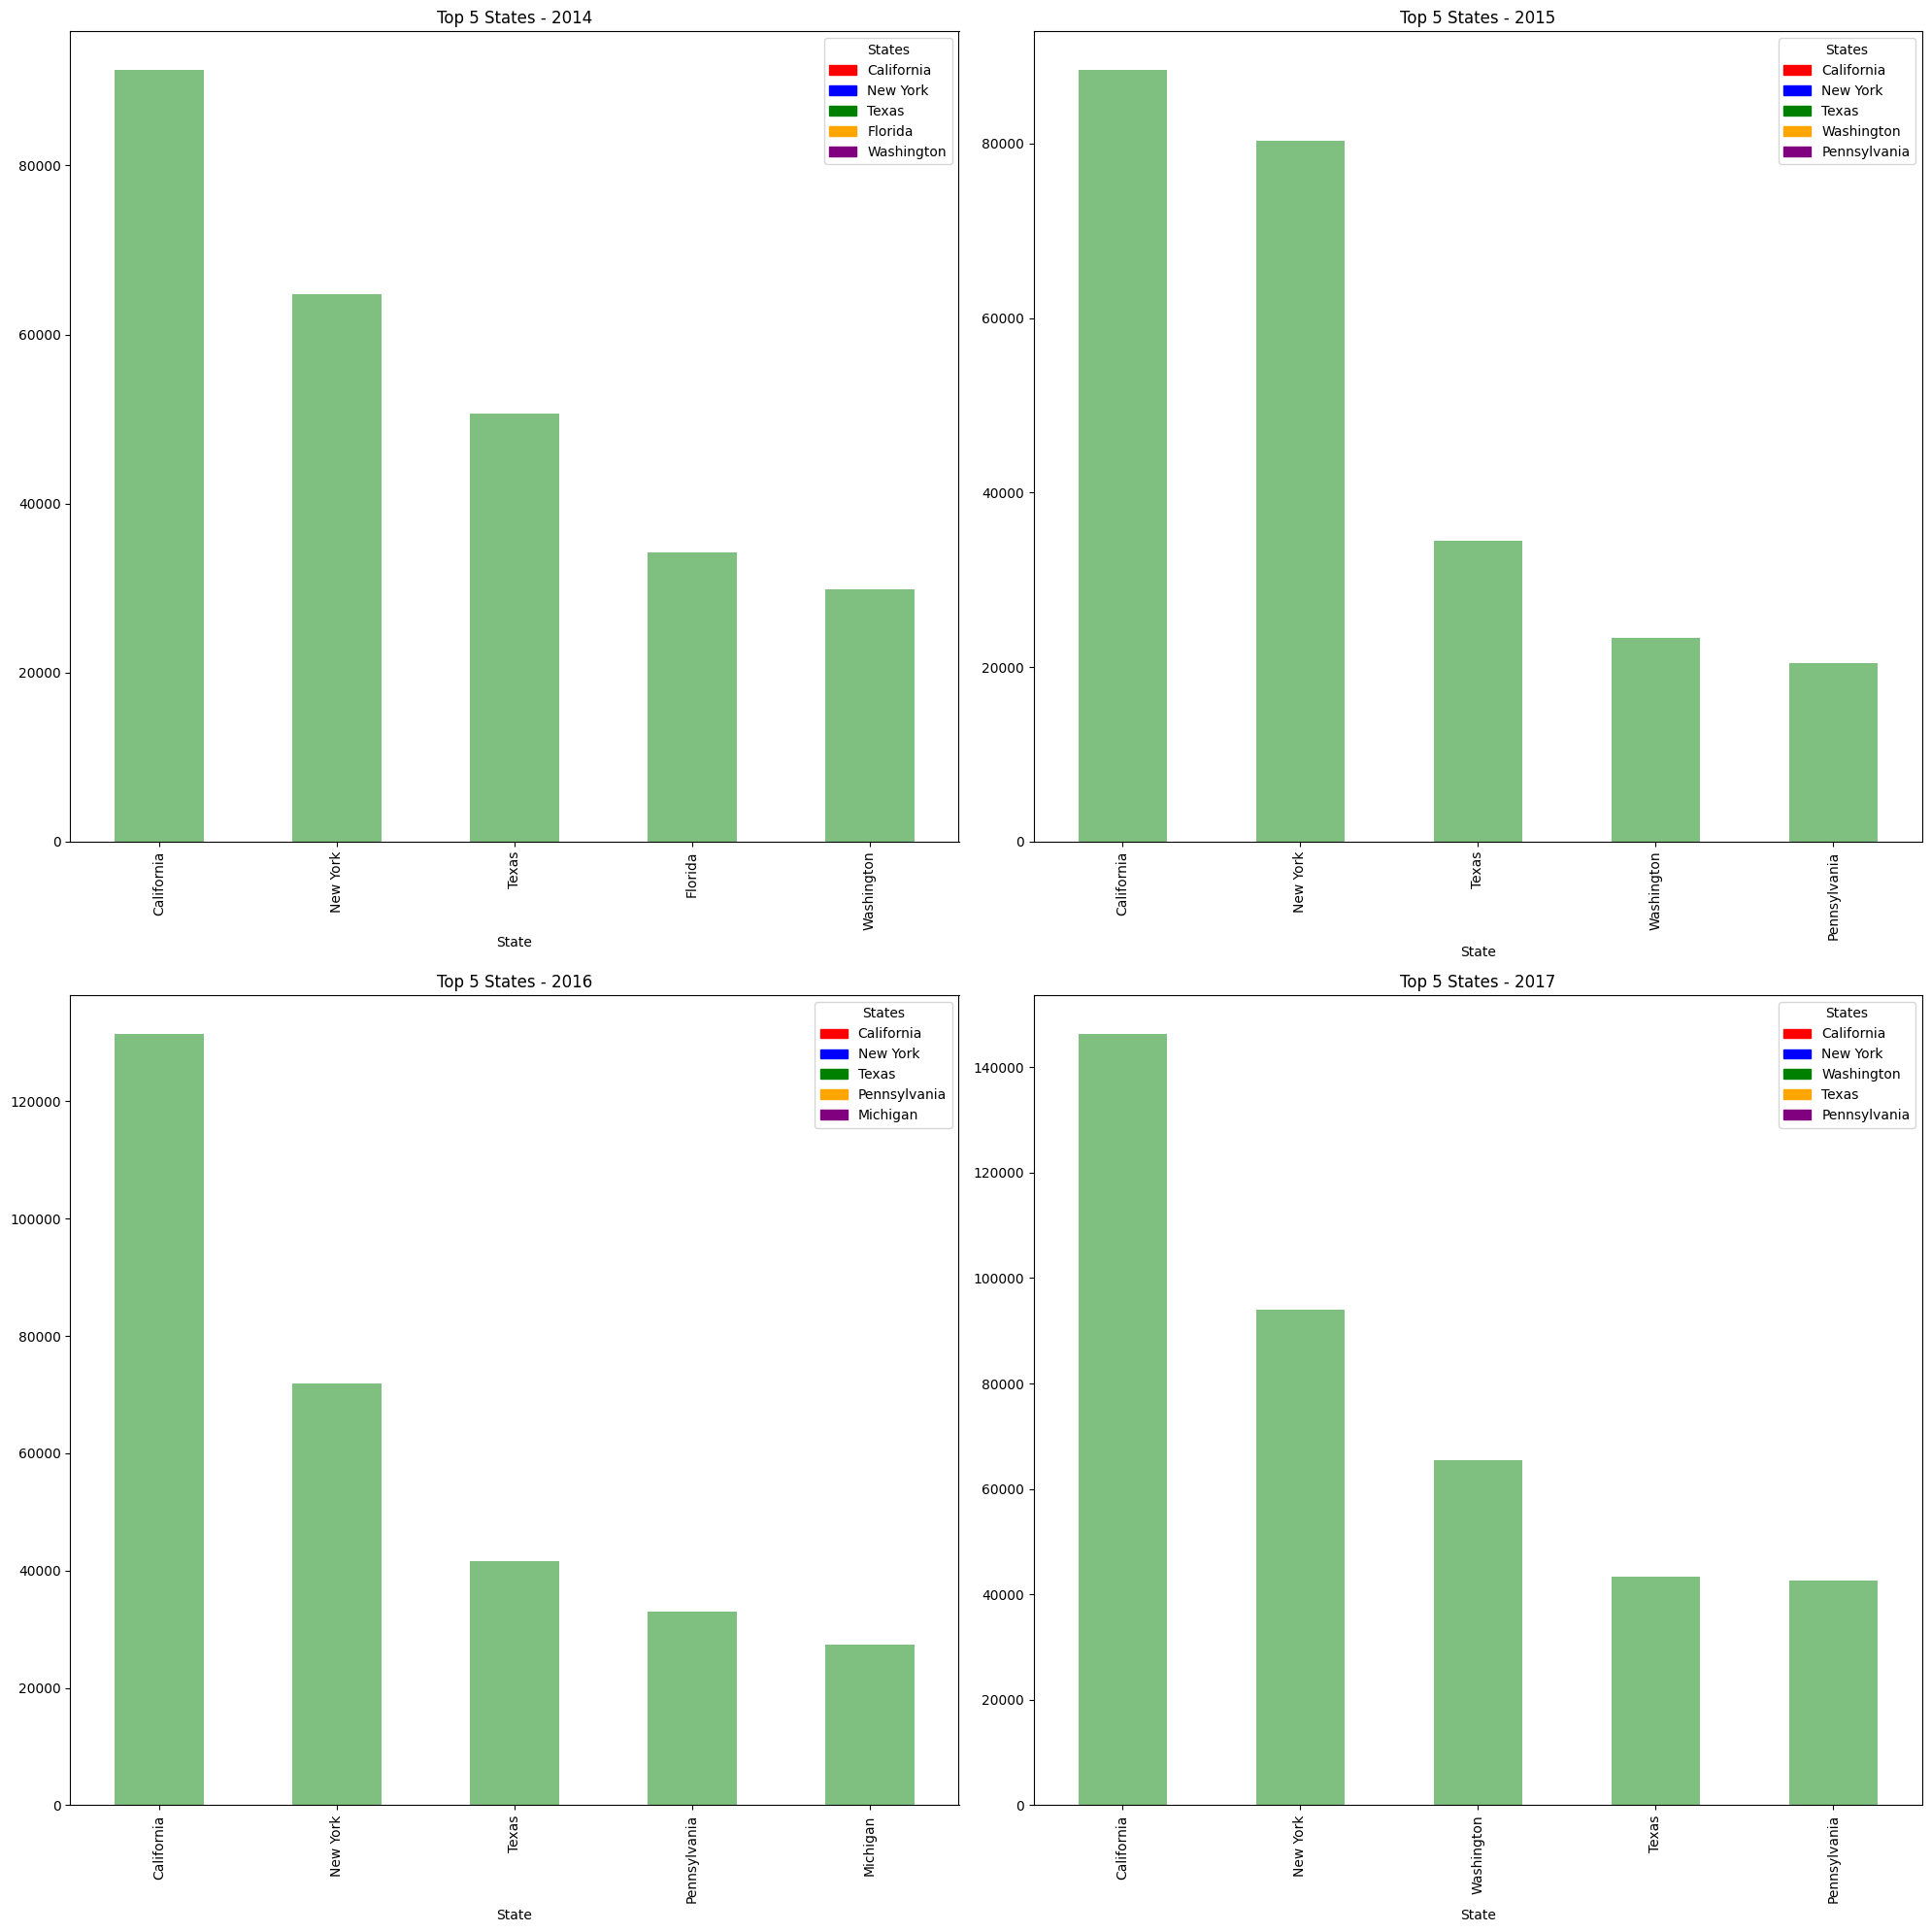

In [28]:
from matplotlib.patches import Patch
colors = ['red', 'blue', 'green', 'orange', 'purple']
# use subplot to plot the histogram
years = top5_states['year_order_date'].unique()

fig, axes = plt.subplots(
    nrows=int(len(years)/2),
    ncols=int(len(years)//2),
    figsize=(20, 5 * len(years))
)

axes=axes.flatten()

# If there's only one year, make axes iterable
if len(years) == 1:
    axes = [axes]

for ax, year in zip(axes, years):
    data = top5_states[top5_states['year_order_date'] == year]
    
    
    data.plot(
        kind='bar',
        x='State',
        y='Sales',
        ax=ax,
        color='green',
        legend=True,
        title=f'Top 5 States - {year}',
        alpha=0.5
        
    )
    handles = [
        Patch(color=colors[i], label=state)
        for i, state in enumerate(data['State'])
    ]
    ax.legend(handles=handles, title='States')
    


plt.tight_layout() # alows the label to not overlap
plt.show()

# inthe case of conflict between 

In [29]:
category_values =df['Category'].value_counts()
category_values



Category
Office Supplies    6026
Furniture          2121
Technology         1847
Name: count, dtype: int64

In [30]:
type(category_values)

pandas.Series

Text(0.5, 1.0, 'Pie Chart -Category Value count')

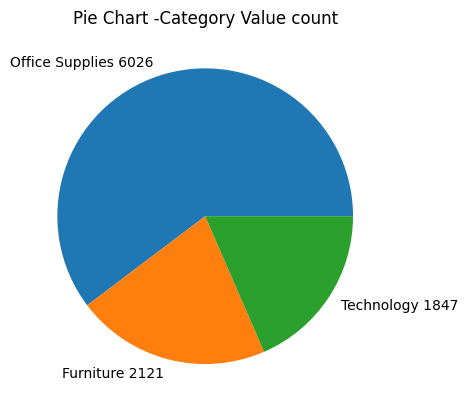

In [31]:
plt.pie(category_values.values,labels=category_values.index+ " "+category_values.values.astype('str'))
plt.title("Pie Chart -Category Value count")


category_values.index is a Pandas Index of strings, while category_values.values is a NumPy array of numbers. You can't concatenate strings and integers/floats directly.

Fix 2 (Recommended): Use a list comprehension

This gives you more control over the label format.

labels = [f"{cat}: {val}" for cat, val in zip(category_values.index, category_values.values)]

plt.pie(category_values.values, labels=labels)
plt.title("Pie Chart - Category Value Count")

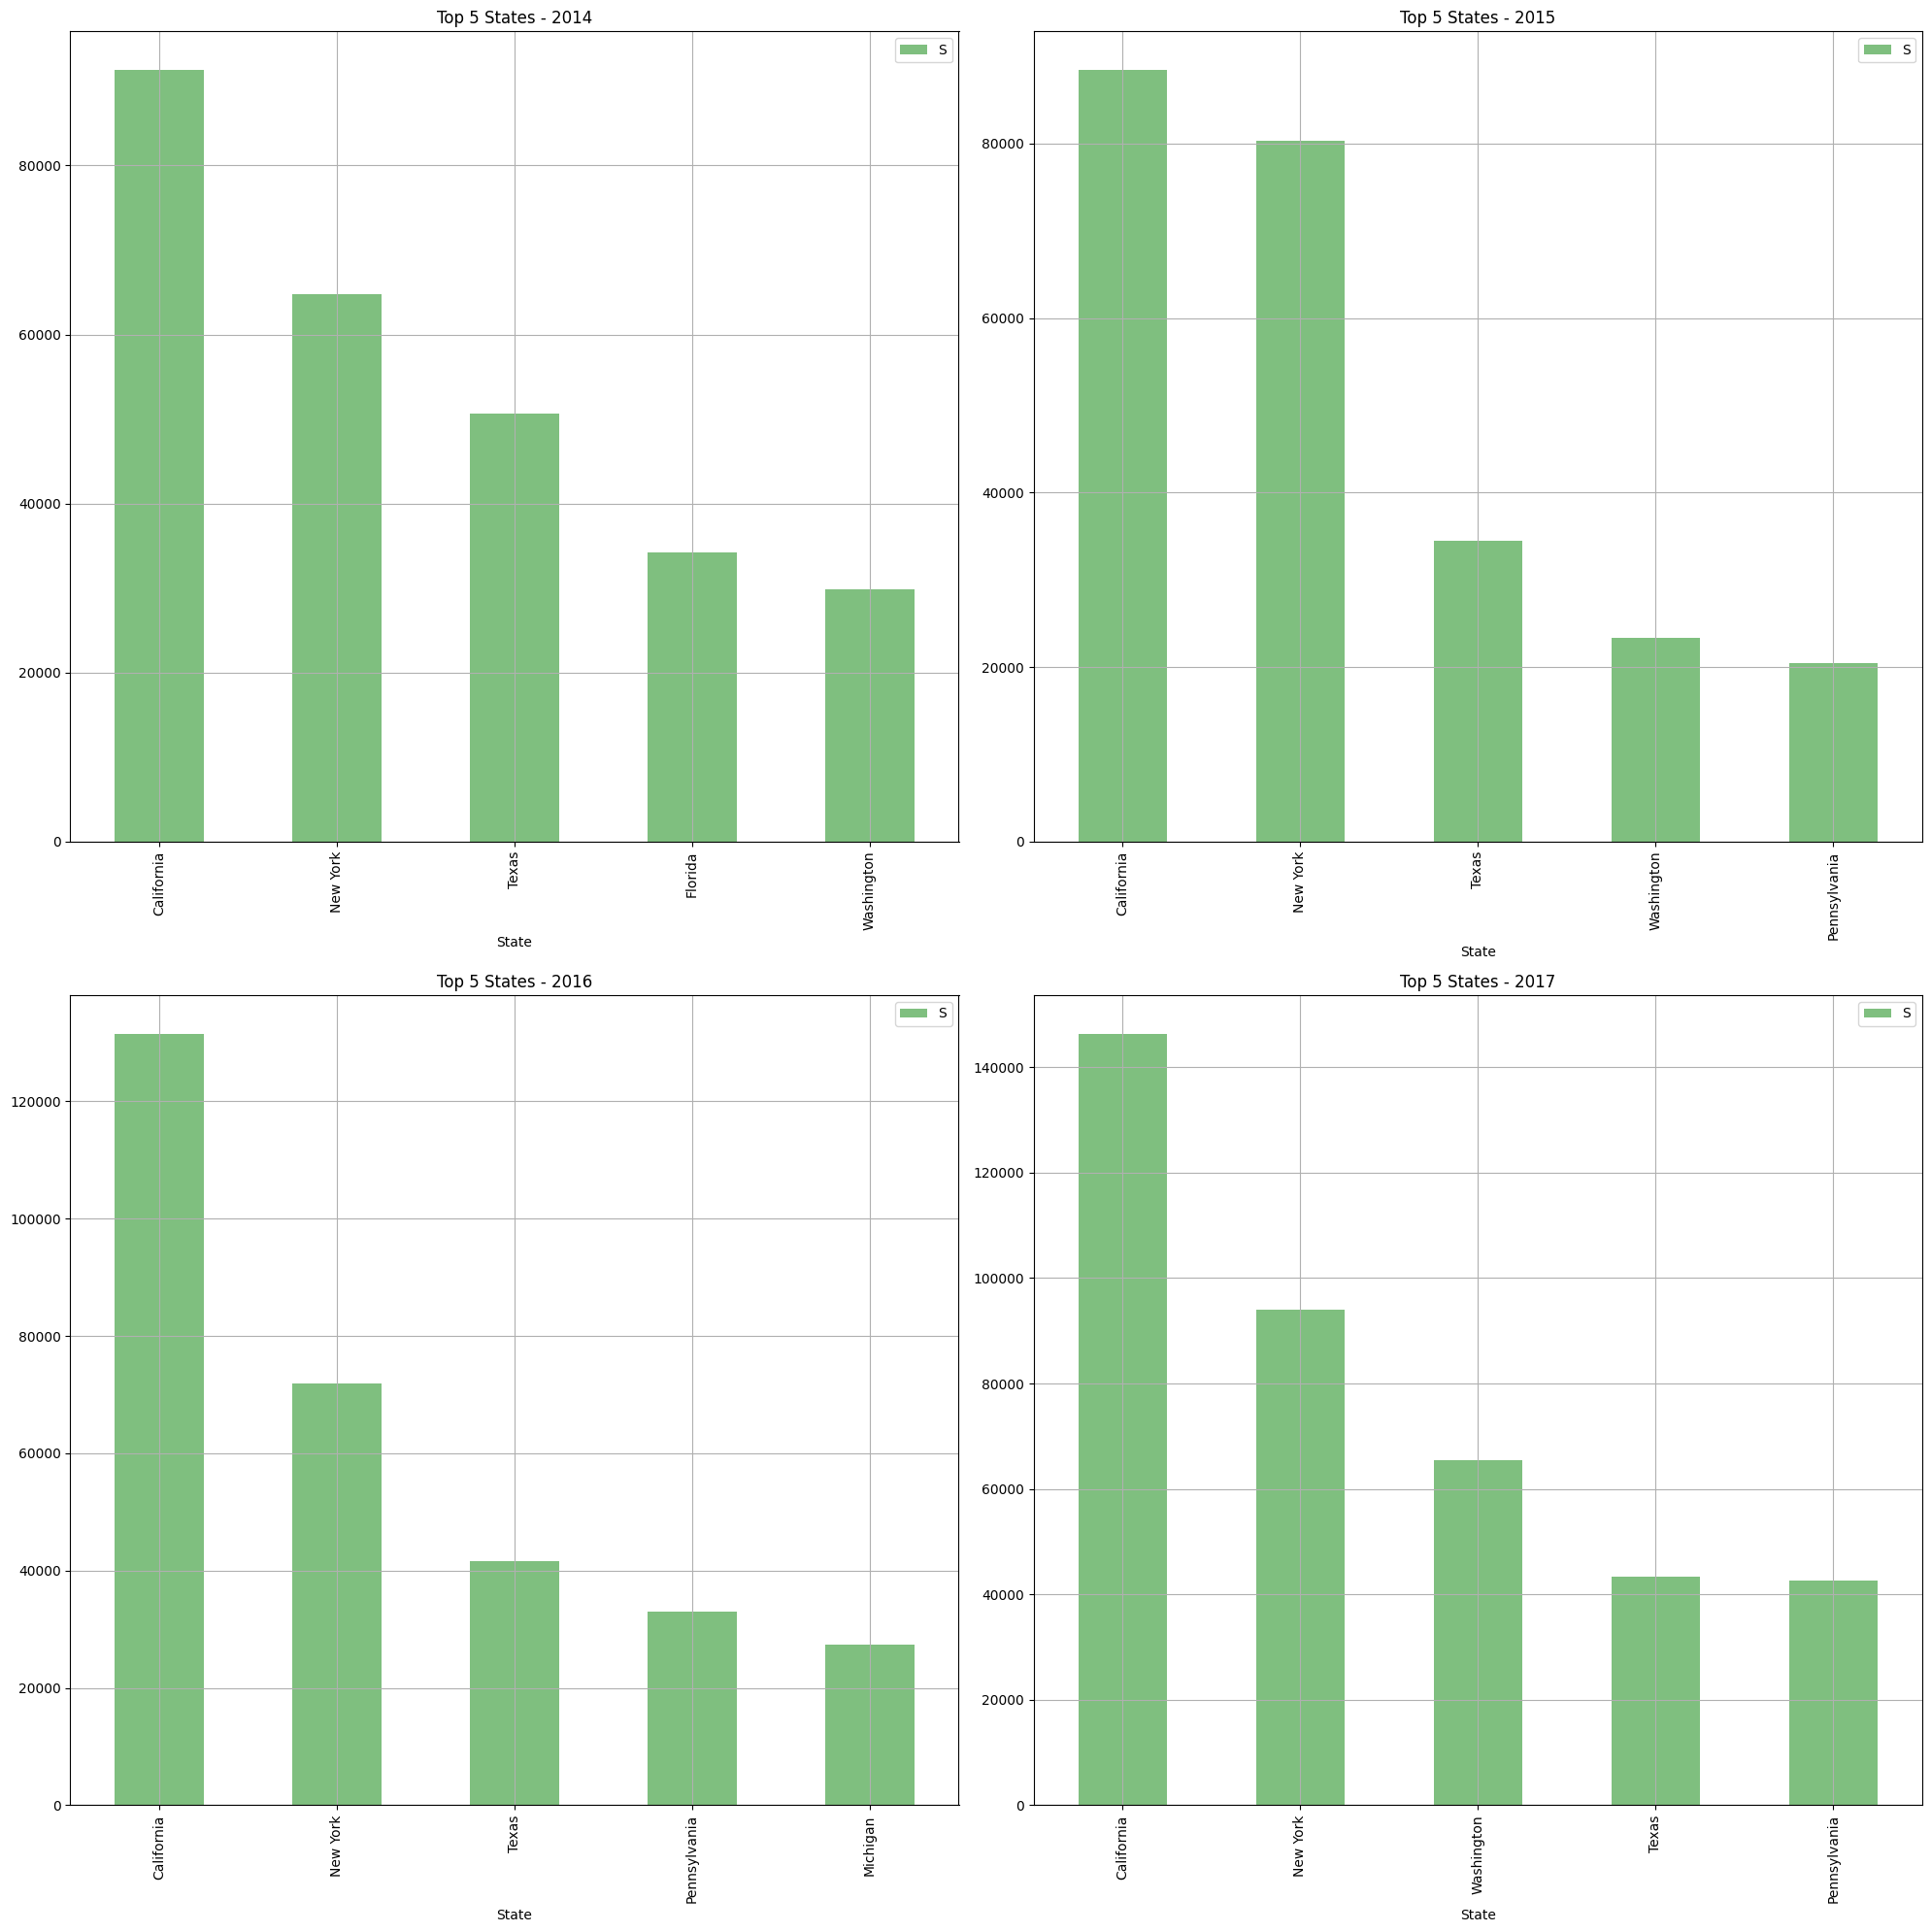

In [32]:
# use subplot to plot the histogram
years = top5_states['year_order_date'].unique()

fig, axes = plt.subplots(
    nrows=int(len(years)/2),
    ncols=int(len(years)//2),
    figsize=(20, 5 * len(years))
)

axes=axes.flatten()

# If there's only one year, make axes iterable
if len(years) == 1:
    axes = [axes]

for ax, year in zip(axes, years):
    data = top5_states[top5_states['year_order_date'] == year]
    
    data.plot(
        kind='bar',
        x='State',
        y='Sales',
        ax=ax,
        color='green',
        legend=False,
        title=f'Top 5 States - {year}',
        alpha=0.5,
        
    )
    ax.grid()
    ax.legend('State')


plt.tight_layout() # alows the label to not overlap
plt.show()

# inthe case of conflict between 

inside a loop while using subplots. plt.grid() acts on the current axes, which may not be the ax you're plotting to. As a result, the grid often only appears on the last active subplot.

so instead of plt.grid use ax.grid

s

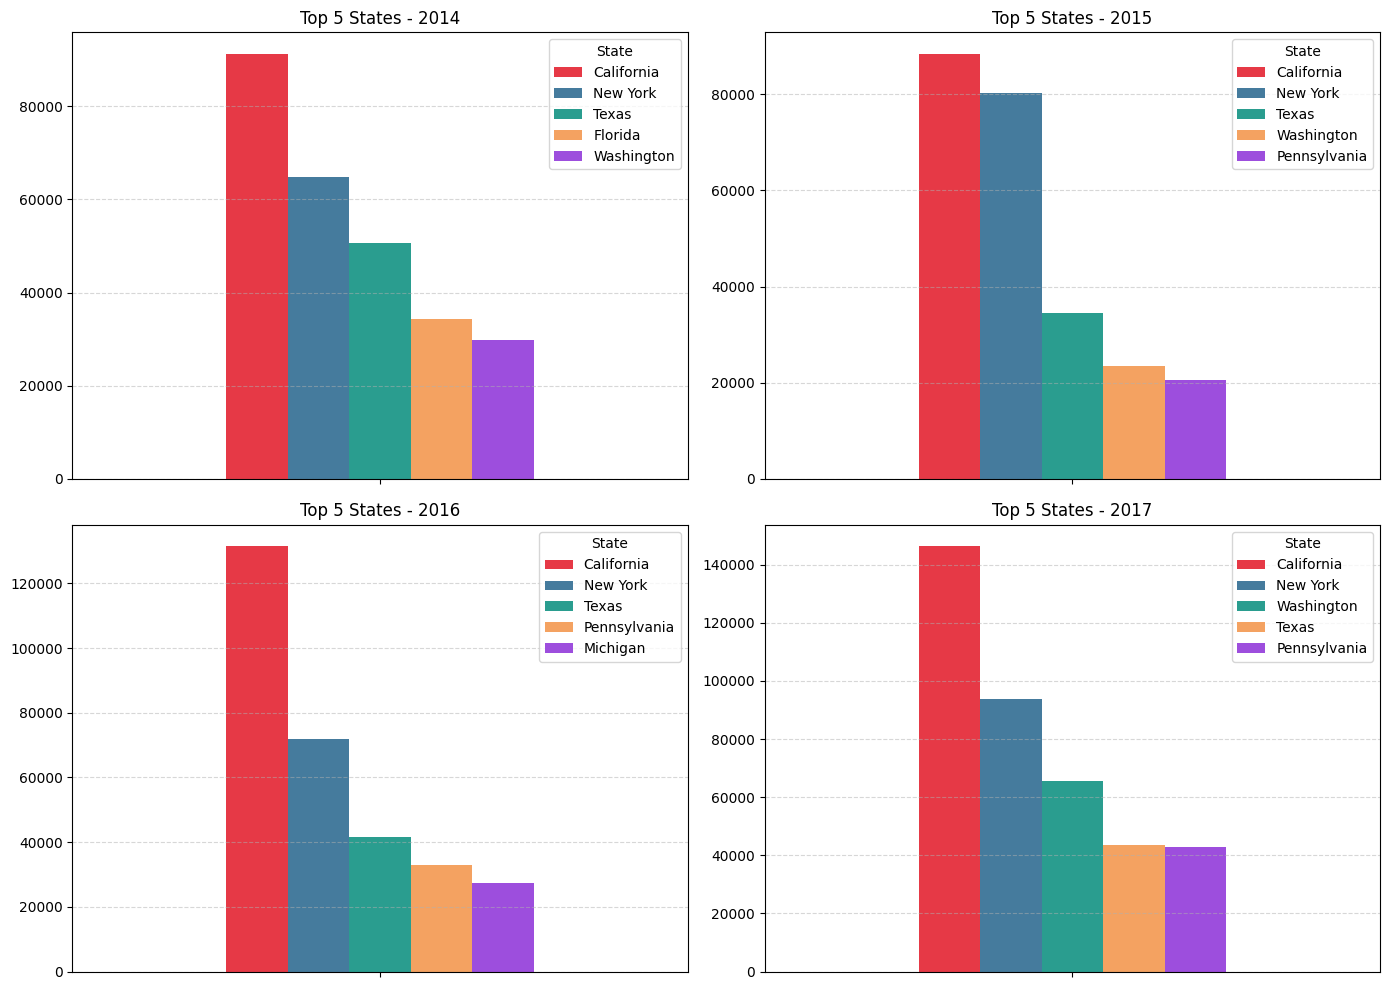

In [33]:
import matplotlib.pyplot as plt

colors = ['#e63946', '#457b9d', '#2a9d8f', '#f4a261', '#9d4edd']
years = top5_states['year_order_date'].unique()

ncols = 2
nrows = (len(years) + ncols - 1) // ncols

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(14, 5 * nrows))
axes = axes.flatten() if hasattr(axes, 'flatten') else [axes]

for ax, year in zip(axes, years):
    data = top5_states[top5_states['year_order_date'] == year]
    
    # 1. Set 'State' as index & transpose (.T)
    # This tricks Pandas into treating each State as its own data series!
    chart_data = data.set_index('State')[['Sales']].T
    
    # 2. Plotting handles colors & legend automatically
    chart_data.plot(
        kind='bar',
        ax=ax,
        color=colors[:len(data)],
        rot=0,  # Keeps x-axis labels horizontal
        title=f'Top 5 States - {year}'
    )
    
    ax.set_xticklabels([])  # Hide the 'Sales' label on x-axis
    ax.grid(axis='y', linestyle='--', alpha=0.5)

# Clean up empty subplots
for unused_ax in axes[len(years):]:
    fig.delaxes(unused_ax)

plt.tight_layout()
plt.show()
# inthe case of conflict between 

Here is why hasattr() was useful there:If you have a grid (e.g., $2 \times 2$ subplots): plt.subplots() returns a NumPy array. A NumPy array has the .flatten() method. So hasattr(axes, 'flatten') evaluates to True, and it squashes the grid into a 1D list.If you only have 1 plot (e.g., nrows=1, ncols=1): plt.subplots() returns a single Axes object. A single Axes object does NOT have a .flatten() method.

Without hasattr(), calling axes.flatten() on a single plot would crash your script with an AttributeError: 'AxesSubplot' object has no attribute 'flatten'

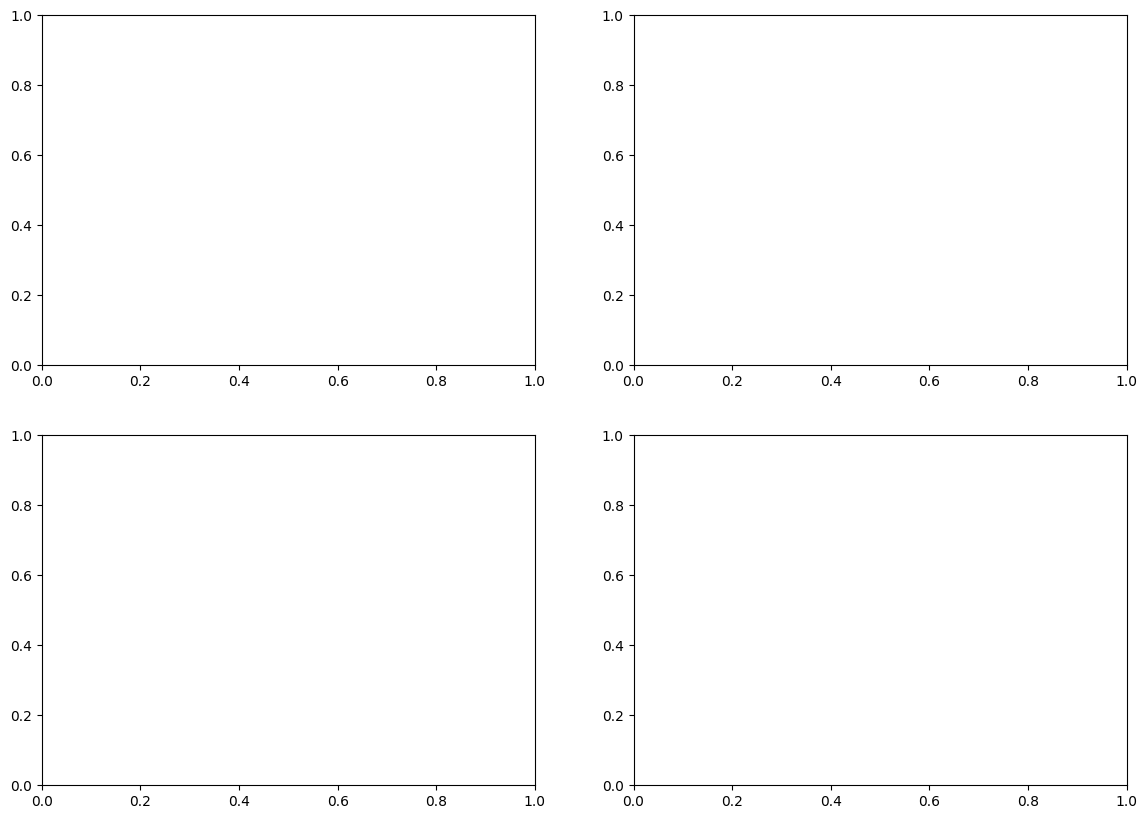

In [34]:
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(14, 5 * nrows))

In [35]:
type(years)

numpy.ndarray